# Proyecto de Deep Learning - Deteccion de spam con una red LSTM

**Materia:** Inteligencia Artificial (Machine Learning y Deep Learning)
**Estudiante:** David Tellez
**Programa:** Ingenieria de Software - Noveno semestre

En este proyecto entreno una red recurrente (LSTM) para clasificar mensajes de texto SMS y decidir si son spam o mensajes normales. Al final guardo el modelo para usarlo desde una aplicacion hecha en Streamlit.

Escogi un problema de texto porque las redes recurrentes estan hechas justamente para datos secuenciales, y un mensaje es una secuencia de palabras donde el orden importa. No es lo mismo "free call me" que "call me free".

Contenido:

1. Librerias
2. Seleccion y descripcion del dataset
3. Analisis exploratorio
4. Limpieza y preprocesamiento
5. Division en entrenamiento, validacion y prueba
6. Construccion y entrenamiento de la LSTM
7. Graficas del entrenamiento
8. Evaluacion con metricas
9. Matriz de confusion y curva ROC
10. Predicciones de prueba
11. Guardado del modelo

## 1. Librerias

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)

np.random.seed(42)
tf.random.set_seed(42)

print("Version de TensorFlow:", tf.__version__)

I0000 00:00:1791157107.387570     678 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791157107.433766     678 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791157108.442144     678 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Version de TensorFlow: 2.21.0


## 2. Seleccion y descripcion del dataset

Use el **SMS Spam Collection**, que es un dataset publico de la UCI con mensajes de texto reales recolectados en Reino Unido. Cada mensaje viene etiquetado como:

- **ham**: mensaje normal
- **spam**: publicidad, estafas, premios falsos, suscripciones, etc.

Lo escogi porque es un problema real y facil de entender, los mensajes son cortos (perfecto para una LSTM sin necesitar una GPU) y ademas da para hacer una app bonita donde uno escribe un mensaje y ve el resultado al instante.

El archivo lo cargo directamente desde GitHub, asi funciona igual en Colab y en el computador.

In [2]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(URL, sep="\t", header=None, names=["etiqueta", "mensaje"])

print("Total de mensajes:", len(df))
df.head(10)

Total de mensajes: 5572


,etiqueta,mensaje
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [3]:
print(df["etiqueta"].value_counts())
print()
print(df["etiqueta"].value_counts(normalize=True) * 100)

etiqueta
ham     4825
spam     747
Name: count, dtype: int64

etiqueta
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


Aca ya se ve algo importante: el dataset esta **desbalanceado**. Como el 87% son mensajes normales y solo el 13% son spam. Eso hay que tenerlo en cuenta despues, porque si un modelo dijera "todo es ham" ya tendria 87% de accuracy sin haber aprendido nada. Por eso mas adelante no me voy a quedar solo con el accuracy.

## 3. Analisis exploratorio

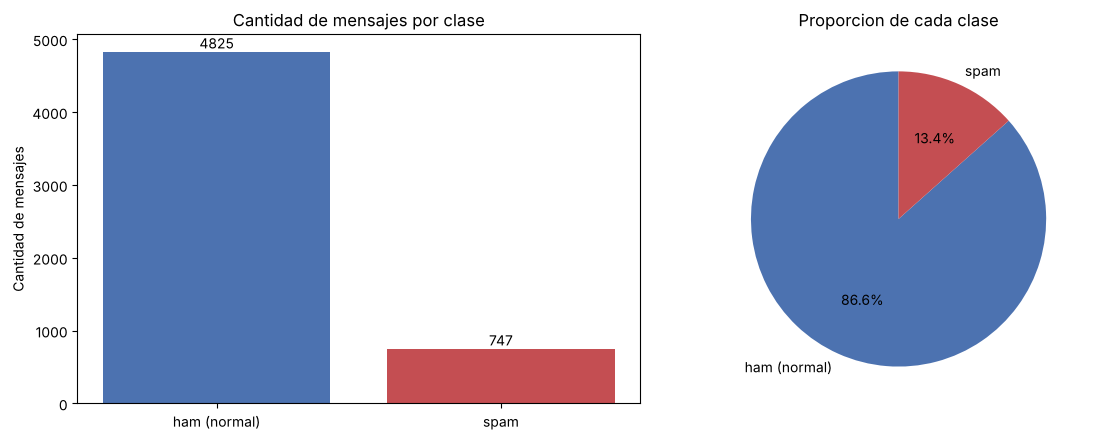

In [4]:
conteo = df["etiqueta"].value_counts()

fig, (g1, g2) = plt.subplots(1, 2, figsize=(12, 4.5))
g1.bar(["ham (normal)", "spam"], [conteo["ham"], conteo["spam"]], color=["#4c72b0", "#c44e52"])
g1.set_ylabel("Cantidad de mensajes")
g1.set_title("Cantidad de mensajes por clase")
for i, v in enumerate([conteo["ham"], conteo["spam"]]):
    g1.text(i, v + 50, str(v), ha="center")

g2.pie([conteo["ham"], conteo["spam"]], labels=["ham (normal)", "spam"],
       autopct="%1.1f%%", colors=["#4c72b0", "#c44e52"], startangle=90)
g2.set_title("Proporcion de cada clase")

plt.tight_layout()
plt.show()

In [5]:
# miro el largo de los mensajes, a ver si hay diferencia entre spam y ham
df["largo"] = df["mensaje"].apply(lambda t: len(str(t).split()))

print("Largo promedio ham:  %.1f palabras" % df[df.etiqueta == "ham"]["largo"].mean())
print("Largo promedio spam: %.1f palabras" % df[df.etiqueta == "spam"]["largo"].mean())
print()
print(df.groupby("etiqueta")["largo"].describe())

Largo promedio ham:  14.3 palabras
Largo promedio spam: 23.9 palabras



           count       mean        std  min   25%   50%   75%    max
etiqueta                                                            
ham       4825.0  14.310259  11.517945  1.0   7.0  11.0  19.0  171.0
spam       747.0  23.911647   5.780174  2.0  22.0  25.0  28.0   35.0


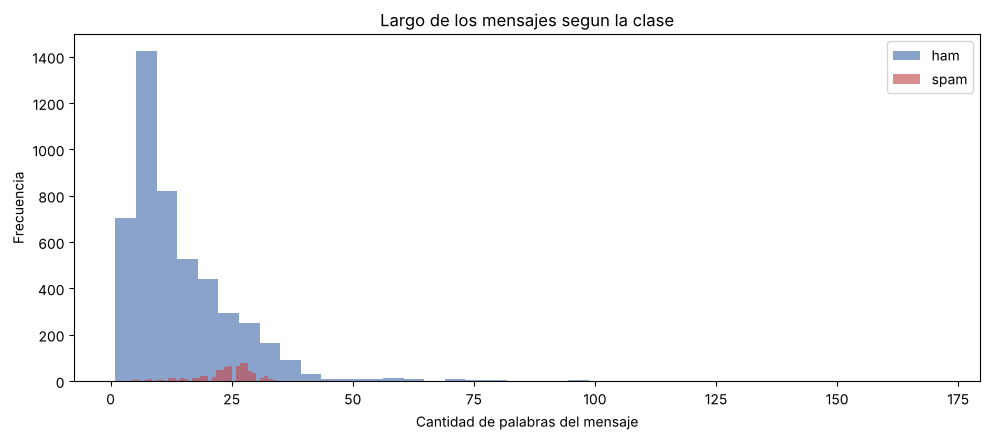

In [6]:
plt.figure(figsize=(10, 4.5))
plt.hist(df[df.etiqueta == "ham"]["largo"], bins=40, alpha=0.65, label="ham", color="#4c72b0")
plt.hist(df[df.etiqueta == "spam"]["largo"], bins=40, alpha=0.65, label="spam", color="#c44e52")
plt.xlabel("Cantidad de palabras del mensaje")
plt.ylabel("Frecuencia")
plt.title("Largo de los mensajes segun la clase")
plt.legend()
plt.tight_layout()
plt.show()

Los mensajes de spam son bastante mas largos (24 palabras en promedio contra 14 de los normales). Tiene logica, el spam trae terminos y condiciones, numeros para llamar, links y toda esa cantidad de texto, mientras que un mensaje entre amigos es corto.

Esto tambien me sirve para decidir hasta cuantas palabras voy a dejar en cada mensaje mas adelante.

In [7]:
# unos ejemplos de cada clase para ver con que estoy trabajando
print(">>> MENSAJES NORMALES (ham)\n")
for m in df[df.etiqueta == "ham"]["mensaje"].head(4):
    print("-", m[:110])

print("\n>>> MENSAJES SPAM\n")
for m in df[df.etiqueta == "spam"]["mensaje"].head(4):
    print("-", m[:110])

>>> MENSAJES NORMALES (ham)

- Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..
- Ok lar... Joking wif u oni...
- U dun say so early hor... U c already then say...
- Nah I don't think he goes to usf, he lives around here though

>>> MENSAJES SPAM

- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb o
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! C


## 4. Limpieza y preprocesamiento

Mirando los ejemplos de arriba se nota que el spam esta lleno de numeros de telefono, precios en libras y links. Entonces en vez de borrar todo eso, lo que hago es **reemplazarlo por una palabra clave**. La direccion exacta del link no me dice nada, pero el hecho de que el mensaje traiga un link si es una señal importante, y si borro los numeros pierdo esa pista.

La limpieza hace esto:

- pasa todo a minuscula
- cambia los links por la palabra `link`
- cambia los correos por `correo`
- cambia los numeros largos (telefonos, codigos de premios) por `numerolargo` y los cortos por `numero`
- cambia el simbolo de libras y de dolar por palabras
- quita los signos de puntuacion y los espacios de mas

In [8]:
def limpiar_texto(texto):
    texto = str(texto).lower()
    texto = re.sub(r"http\S+|www\.\S+", " link ", texto)
    texto = re.sub(r"\S+@\S+", " correo ", texto)
    texto = re.sub(r"\b\d{5,}\b", " numerolargo ", texto)
    texto = re.sub(r"\b\d+\b", " numero ", texto)
    texto = texto.replace("£", " libras ")
    texto = texto.replace("$", " dolares ")
    texto = re.sub(r"[^a-z\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


# pruebo la funcion con un mensaje de spam real
ejemplo = df[df.etiqueta == "spam"]["mensaje"].iloc[0]
print("ANTES:")
print(ejemplo)
print("\nDESPUES:")
print(limpiar_texto(ejemplo))

ANTES:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

DESPUES:
free entry in numero a wkly comp to win fa cup final tkts st may numero text fa to numerolargo to receive entry question std txt rate t c s apply over s


In [9]:
df["mensaje_limpio"] = df["mensaje"].apply(limpiar_texto)
df["y"] = (df["etiqueta"] == "spam").astype(int)

# reviso si algun mensaje quedo vacio despues de limpiar
vacios = (df["mensaje_limpio"].str.len() == 0).sum()
print("Mensajes que quedaron vacios:", vacios)
df = df[df["mensaje_limpio"].str.len() > 0].copy()

# y tambien quito los duplicados, encontre varios mensajes repetidos
antes = len(df)
df = df.drop_duplicates(subset="mensaje_limpio").copy()
print("Duplicados eliminados:", antes - len(df))
print("Mensajes que quedan:", len(df))

Mensajes que quedaron vacios: 2
Duplicados eliminados: 475
Mensajes que quedan: 5095


Ahora que el texto esta limpio miro cuales son las palabras mas usadas en cada clase, para ver si el modelo va a tener de donde agarrarse.

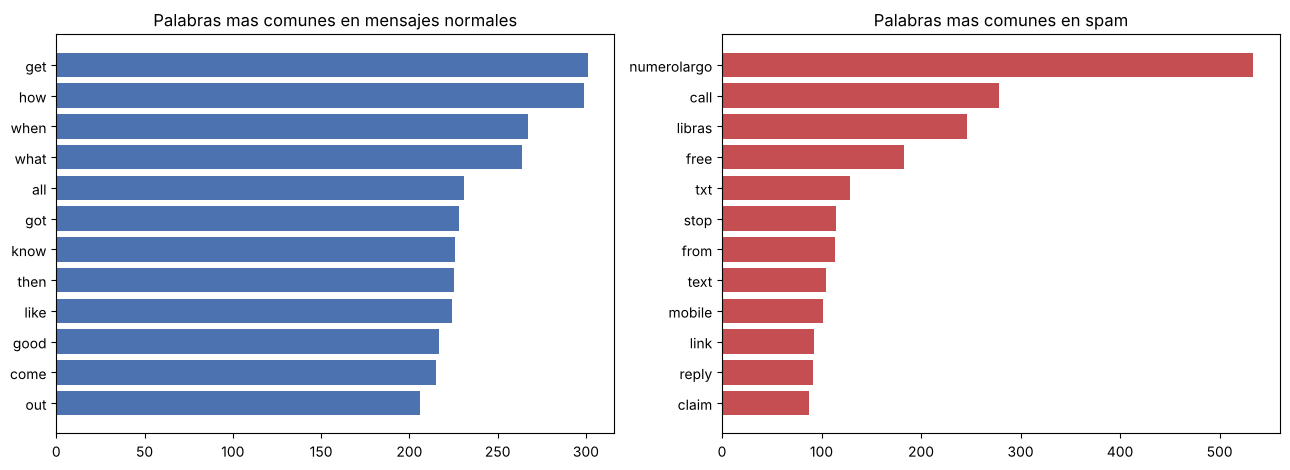

In [10]:
vacias = {"the","to","you","a","i","and","in","is","it","my","of","for","me","that",
          "have","on","are","your","but","not","so","do","be","at","with","will","can",
          "if","we","this","am","its","just","now","no","or","u","numero","s","t"}

def top_palabras(clase, n=12):
    palabras = []
    for m in df[df.etiqueta == clase]["mensaje_limpio"]:
        palabras += [p for p in m.split() if p not in vacias and len(p) > 2]
    return Counter(palabras).most_common(n)

top_ham, top_spam = top_palabras("ham"), top_palabras("spam")

fig, (g1, g2) = plt.subplots(1, 2, figsize=(13, 4.8))
g1.barh([p for p, _ in top_ham][::-1], [c for _, c in top_ham][::-1], color="#4c72b0")
g1.set_title("Palabras mas comunes en mensajes normales")
g2.barh([p for p, _ in top_spam][::-1], [c for _, c in top_spam][::-1], color="#c44e52")
g2.set_title("Palabras mas comunes en spam")
plt.tight_layout()
plt.show()

Las palabras del spam son exactamente las que uno se imagina: *free*, *call*, *claim*, *txt*, *mobile*, *prize*, mas las marcas que yo puse (`numerolargo`, `libras`, `link`). En cambio en los mensajes normales lo que sale es *get*, *like*, *good*, *come*, *know*, o sea lenguaje de conversacion.

Esto me deja tranquilo de que el problema si se puede resolver y que el modelo tiene señales claras de donde aprender.

## 5. Division en entrenamiento, validacion y prueba

Separo asi:
- 70% entrenamiento
- 15% validacion
- 15% prueba

Lo hago en dos pasos: primero saco el 15% de prueba, y de lo que queda saco otro pedazo para validacion. En los dos uso `stratify` para que la proporcion de spam quede igual en los tres conjuntos, porque como hay poquito spam si lo dejo al azar me puede quedar un conjunto con muy pocos.

In [11]:
# ojo con esto: toca usar dtype=object. Si uno pasa el arreglo de texto normal de
# numpy, Keras lo rechaza con un error raro de dtype
x = np.array(df["mensaje_limpio"].tolist(), dtype=object)
y = np.array(df["y"].tolist())

x_tmp, x_test, y_tmp, y_test = train_test_split(
    x, y, test_size=0.15, random_state=42, stratify=y)

x_train, x_val, y_train, y_val = train_test_split(
    x_tmp, y_tmp, test_size=0.1765, random_state=42, stratify=y_tmp)

print("Entrenamiento: %4d mensajes  (spam: %3d)" % (len(x_train), y_train.sum()))
print("Validacion:    %4d mensajes  (spam: %3d)" % (len(x_val), y_val.sum()))
print("Prueba:        %4d mensajes  (spam: %3d)" % (len(x_test), y_test.sum()))

Entrenamiento: 3565 mensajes  (spam: 417)
Validacion:     765 mensajes  (spam:  90)
Prueba:         765 mensajes  (spam:  90)


## 6. Construccion y entrenamiento de la LSTM

### Como paso el texto a numeros

La red no entiende palabras, entonces toca convertir cada mensaje en una lista de numeros. Para eso uso la capa `TextVectorization`, que arma un vocabulario con las palabras mas frecuentes y le asigna un numero a cada una.

La meto **dentro del modelo** en vez de usarla aparte. La ventaja es que cuando guardo el modelo, el vocabulario queda guardado ahi mismo, entonces la app de Streamlit solo tiene que pasarle el texto y listo. Si la usara por fuera tocaria guardar el vocabulario en otro archivo y acordarse de cargarlo, y si se desincroniza el modelo empieza a predecir cualquier cosa.

Configuracion:
- `max_tokens=8000`: solo las 8000 palabras mas frecuentes, las demas quedan como desconocidas
- `output_sequence_length=60`: todos los mensajes quedan de 60 palabras, rellenando con ceros los cortos y recortando los largos. Escogi 60 porque arriba vi que hasta el spam promedia 24 palabras
- `standardize=None`: porque la limpieza ya la hice yo a mano

### La arquitectura

- **Embedding**: convierte cada palabra en un vector de 64 numeros. Aca es donde la red aprende que palabras como "free" y "prize" se parecen entre si
- **Bidirectional LSTM(48)** con `return_sequences=True`: lee el mensaje de izquierda a derecha y tambien de derecha a izquierda, y le pasa la secuencia completa a la siguiente capa
- **Bidirectional LSTM(32)**: esta ya resume todo el mensaje en un solo vector
- **Dense(32)** y una salida **Dense(1) con sigmoid**, que da la probabilidad de que sea spam

Use LSTM y no una RNN simple porque la RNN normal se le olvida lo que leyo al principio cuando el texto se alarga, y las LSTM tienen las compuertas que les permiten acordarse de cosas de mas atras. Y las puse bidireccionales porque en un mensaje el contexto importa en los dos sentidos.

In [12]:
MAX_PALABRAS = 8000
LARGO_MAX = 60

vectorizador = layers.TextVectorization(
    max_tokens=MAX_PALABRAS,
    output_sequence_length=LARGO_MAX,
    standardize=None,
    name="vectorizador"
)
vectorizador.adapt(x_train)

print("Tamaño real del vocabulario:", len(vectorizador.get_vocabulary()))
print("Primeras palabras del vocabulario:", vectorizador.get_vocabulary()[:15])

Tamaño real del vocabulario: 6360
Primeras palabras del vocabulario: ['', '[UNK]', np.str_('i'), np.str_('you'), np.str_('to'), np.str_('numero'), np.str_('a'), np.str_('the'), np.str_('u'), np.str_('and'), np.str_('in'), np.str_('is'), np.str_('me'), np.str_('my'), np.str_('for')]


In [13]:
# miro como queda un mensaje convertido en numeros
ejemplo = x_train[0]
print("Mensaje:", ejemplo)
print()
print("Convertido:", vectorizador([ejemplo]).numpy()[0])

Mensaje: its a site to simulate the test it just gives you very tough questions to test your readiness

Convertido: [  69    6 1340    4 3685    7  521   15   39 2554    3  182 1165 1368
    4  521   16 3973    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0]


In [14]:
modelo = keras.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizador,
    layers.Embedding(MAX_PALABRAS, 64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(48, return_sequences=True)),
    layers.Dropout(0.3),
    layers.Bidirectional(layers.LSTM(32)),
    layers.Dropout(0.4),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="lstm_spam")

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

modelo.summary()

Model: "lstm_spam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vectorizador                    │ (None, 60)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 60, 64)         │       512,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 60, 96)         │        43,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,529 (2.25 MB)

 Trainable params: 590,529 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

Uso `binary_crossentropy` porque son solo dos clases, y ademas de accuracy pido precision y recall para poder ir viendo durante el entrenamiento como va con la clase spam, que es la que importa.

Como el dataset esta desbalanceado le pongo pesos a las clases. Basicamente le digo a la red que equivocarse en un spam le cuesta como 4 veces mas que equivocarse en un ham, para que no le de por decir "ham" siempre.

In [15]:
n = len(y_train)
pesos = {0: n / (2 * (n - y_train.sum())), 1: n / (2 * y_train.sum())}
print("Pesos por clase:", pesos)

Pesos por clase: {0: np.float64(0.5662325285895807), 1: np.float64(4.2745803357314145)}


In [16]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]

historial = modelo.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    class_weight=pesos,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/15


E0000 00:00:1791157116.308843     678 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


112/112 - 13s - 113ms/step - accuracy: 0.8107 - loss: 0.3145 - precision: 0.3762 - recall: 0.9400 - val_accuracy: 0.9333 - val_loss: 0.2098 - val_precision: 0.6383 - val_recall: 1.0000 - learning_rate: 0.0010


Epoch 2/15


112/112 - 9s - 82ms/step - accuracy: 0.9835 - loss: 0.0768 - precision: 0.8891 - recall: 0.9808 - val_accuracy: 0.9882 - val_loss: 0.0472 - val_precision: 0.9551 - val_recall: 0.9444 - learning_rate: 0.0010


...

112/112 - 5s - 48ms/step - accuracy: 0.9964 - loss: 0.0128 - precision: 0.9720 - recall: 0.9976 - val_accuracy: 0.9843 - val_loss: 0.0534 - val_precision: 0.9239 - val_recall: 0.9444 - learning_rate: 0.0010


Epoch 6/15


112/112 - 10s - 93ms/step - accuracy: 1.0000 - loss: 0.0024 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9843 - val_loss: 0.0756 - val_precision: 0.9239 - val_recall: 0.9444 - learning_rate: 0.0010


Epoch 7/15


112/112 - 10s - 89ms/step - accuracy: 1.0000 - loss: 0.0014 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9856 - val_loss: 0.0744 - val_precision: 0.9341 - val_recall: 0.9444 - learning_rate: 5.0000e-04


Se nota que el EarlyStopping corto el entrenamiento antes de las 15 epocas. Esto pasa porque el dataset es chiquito (3500 mensajes de entrenamiento) y la red aprende muy rapido, entonces despues de unas pocas epocas ya se empieza a sobreajustar y la perdida de validacion sube en vez de bajar.

## 7. Graficas del entrenamiento

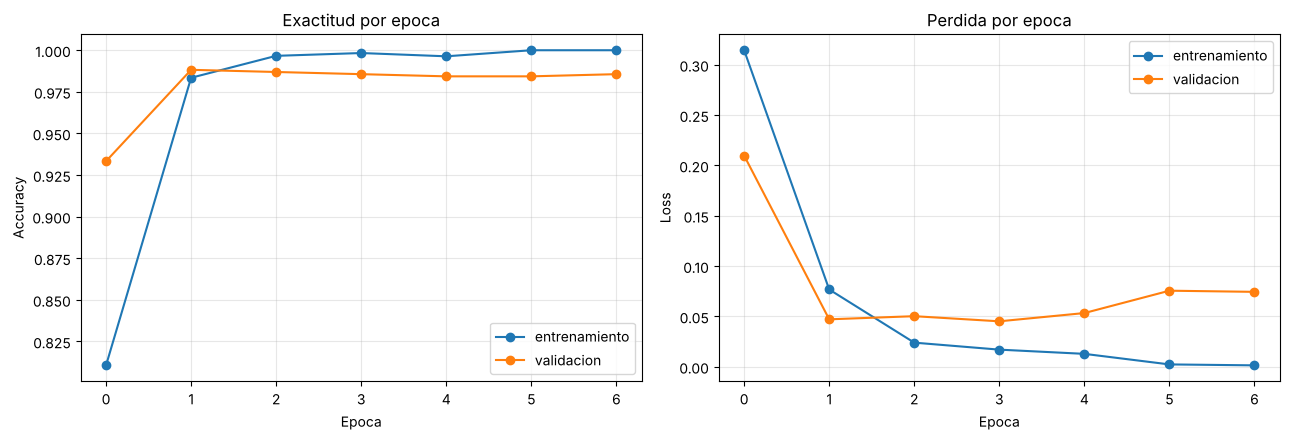

In [17]:
fig, (g1, g2) = plt.subplots(1, 2, figsize=(13, 4.5))

g1.plot(historial.history["accuracy"], label="entrenamiento", marker="o")
g1.plot(historial.history["val_accuracy"], label="validacion", marker="o")
g1.set_title("Exactitud por epoca")
g1.set_xlabel("Epoca"); g1.set_ylabel("Accuracy")
g1.legend(); g1.grid(alpha=0.3)

g2.plot(historial.history["loss"], label="entrenamiento", marker="o")
g2.plot(historial.history["val_loss"], label="validacion", marker="o")
g2.set_title("Perdida por epoca")
g2.set_xlabel("Epoca"); g2.set_ylabel("Loss")
g2.legend(); g2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

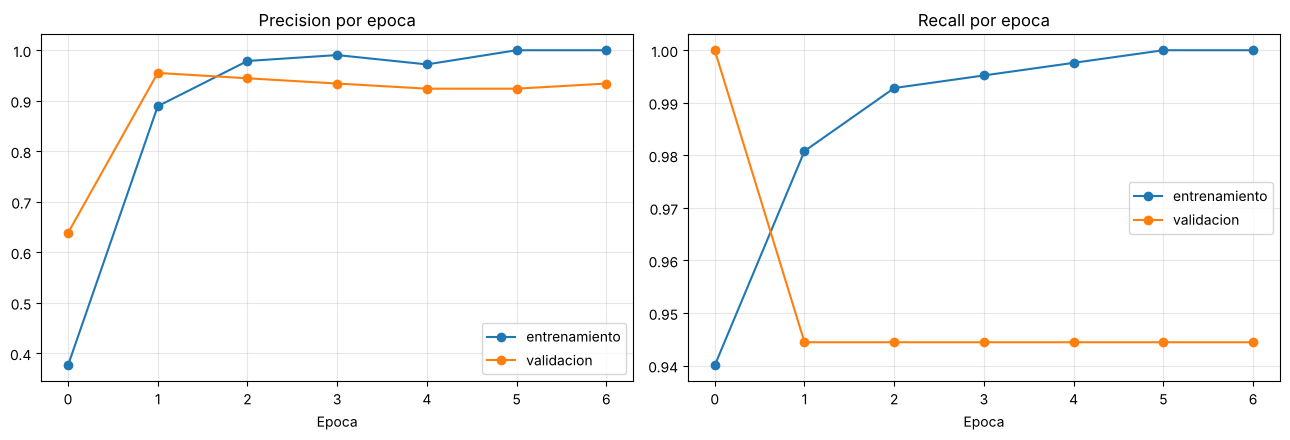

In [18]:
# tambien grafico precision y recall, que para spam son mas importantes que el accuracy
fig, (g1, g2) = plt.subplots(1, 2, figsize=(13, 4.5))

g1.plot(historial.history["precision"], label="entrenamiento", marker="o")
g1.plot(historial.history["val_precision"], label="validacion", marker="o")
g1.set_title("Precision por epoca"); g1.set_xlabel("Epoca")
g1.legend(); g1.grid(alpha=0.3)

g2.plot(historial.history["recall"], label="entrenamiento", marker="o")
g2.plot(historial.history["val_recall"], label="validacion", marker="o")
g2.set_title("Recall por epoca"); g2.set_xlabel("Epoca")
g2.legend(); g2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Evaluacion con metricas

Para este problema el accuracy solo no sirve mucho, porque como el 87% son ham, un modelo bobo que dijera siempre "ham" ya sacaria 87%. Entonces miro tambien:

- **Precision**: de los mensajes que marco como spam, cuantos de verdad eran spam. Si esta baja, el modelo esta mandando mensajes buenos a la carpeta de spam, que es el error que mas molesta a un usuario.
- **Recall**: de todos los spam que habia, cuantos alcanzo a detectar. Si esta bajo, se le estan colando mensajes de spam a la bandeja de entrada.
- **F1-score**: el balance entre las dos.
- **ROC-AUC**: que tan bien separa las dos clases sin importar el umbral que uno escoja.

In [19]:
probabilidades = modelo.predict(x_test, verbose=0).flatten()
y_pred = (probabilidades >= 0.5).astype(int)

print("Accuracy:  %.4f" % accuracy_score(y_test, y_pred))
print("Precision: %.4f" % precision_score(y_test, y_pred))
print("Recall:    %.4f" % recall_score(y_test, y_pred))
print("F1-score:  %.4f" % f1_score(y_test, y_pred))
print("ROC-AUC:   %.4f" % roc_auc_score(y_test, probabilidades))

Accuracy:  0.9804
Precision: 0.9310
Recall:    0.9000
F1-score:  0.9153
ROC-AUC:   0.9859


In [20]:
print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))

              precision    recall  f1-score   support

         ham     0.9867    0.9911    0.9889       675
        spam     0.9310    0.9000    0.9153        90

    accuracy                         0.9804       765
   macro avg     0.9589    0.9456    0.9521       765
weighted avg     0.9802    0.9804    0.9802       765



## 9. Matriz de confusion y curva ROC

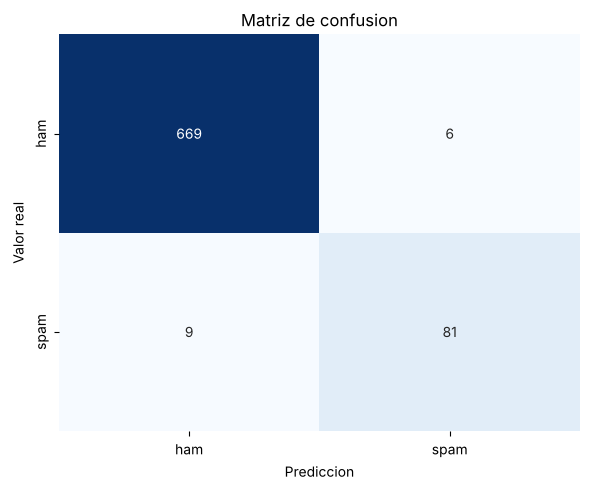

Verdaderos negativos (ham bien clasificados):  669
Falsos positivos (ham que marco como spam):    6
Falsos negativos (spam que se le colo):        9
Verdaderos positivos (spam detectado):         81


In [21]:
mc = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Prediccion"); plt.ylabel("Valor real")
plt.title("Matriz de confusion")
plt.tight_layout()
plt.show()

vn, fp, fn, vp = mc.ravel()
print("Verdaderos negativos (ham bien clasificados): ", vn)
print("Falsos positivos (ham que marco como spam):   ", fp)
print("Falsos negativos (spam que se le colo):       ", fn)
print("Verdaderos positivos (spam detectado):        ", vp)

De los dos tipos de error el que mas duele es el **falso positivo**, o sea un mensaje normal que termina marcado como spam, porque el usuario puede perder un mensaje importante. El falso negativo es molesto pero no tan grave, uno simplemente ve la publicidad y la borra.

Por eso en la app de Streamlit deje un control para mover el umbral: si uno lo sube, el modelo se vuelve mas exigente para marcar algo como spam y bajan los falsos positivos.

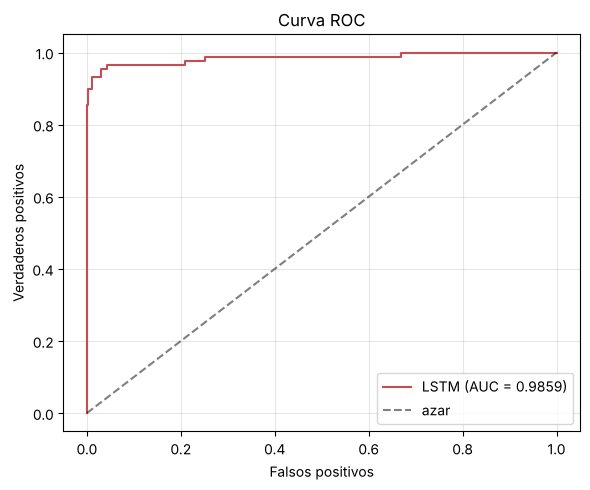

In [22]:
fpr, tpr, _ = roc_curve(y_test, probabilidades)
auc = roc_auc_score(y_test, probabilidades)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#c44e52", label="LSTM (AUC = %.4f)" % auc)
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="azar")
plt.xlabel("Falsos positivos"); plt.ylabel("Verdaderos positivos")
plt.title("Curva ROC")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Predicciones de prueba

El enunciado pide minimo 10 predicciones. Saco 6 ham y 6 spam a proposito, porque si los cojo completamente al azar casi todos salen ham (por el desbalance del dataset) y no se alcanza a ver como se comporta con las dos clases.

In [23]:
np.random.seed(5)
idx_ham = np.random.choice(np.where(y_test == 0)[0], 6, replace=False)
idx_spam = np.random.choice(np.where(y_test == 1)[0], 6, replace=False)
indices = np.concatenate([idx_ham, idx_spam])

for i, idx in enumerate(indices):
    p = probabilidades[idx]
    acerto = "ok" if (p >= 0.5) == bool(y_test[idx]) else "FALLO"
    print("%2d) %s" % (i + 1, x_test[idx][:72]))
    print("    Real: %-5s | Predicho: %-5s | Prob. de spam: %6.2f%%  %s\n" %
          ("spam" if y_test[idx] else "ham", "spam" if p >= 0.5 else "ham", p * 100, acerto))

 1) sorry brah just finished the last of my exams what up
    Real: ham   | Predicho: ham   | Prob. de spam:   0.03%  ok

 2) honey sweetheart darling sexy buns sugar plum loverboy i miss you boytoy
    Real: ham   | Predicho: ham   | Prob. de spam:   0.06%  ok

 3) how are you just checking up on you
    Real: ham   | Predicho: ham   | Prob. de spam:   0.40%  ok

 4) even my brother is not like to speak with me they treat me like aids pat
    Real: ham   | Predicho: ham   | Prob. de spam:   0.70%  ok

 5) happy new year to u too
    Real: ham   | Predicho: ham   | Prob. de spam:   0.07%  ok

 6) why de you looking good only
    Real: ham   | Predicho: ham   | Prob. de spam:   0.13%  ok

 7) marvel mobile play the official ultimate spider man game libras numero n
    Real: spam  | Predicho: spam  | Prob. de spam: 100.00%  ok

 8) twinks bears scallies skins and jocks are calling now don t miss the wee
    Real: spam  | Predicho: spam  | Prob. de spam:  99.99%  ok

 9) more people are d

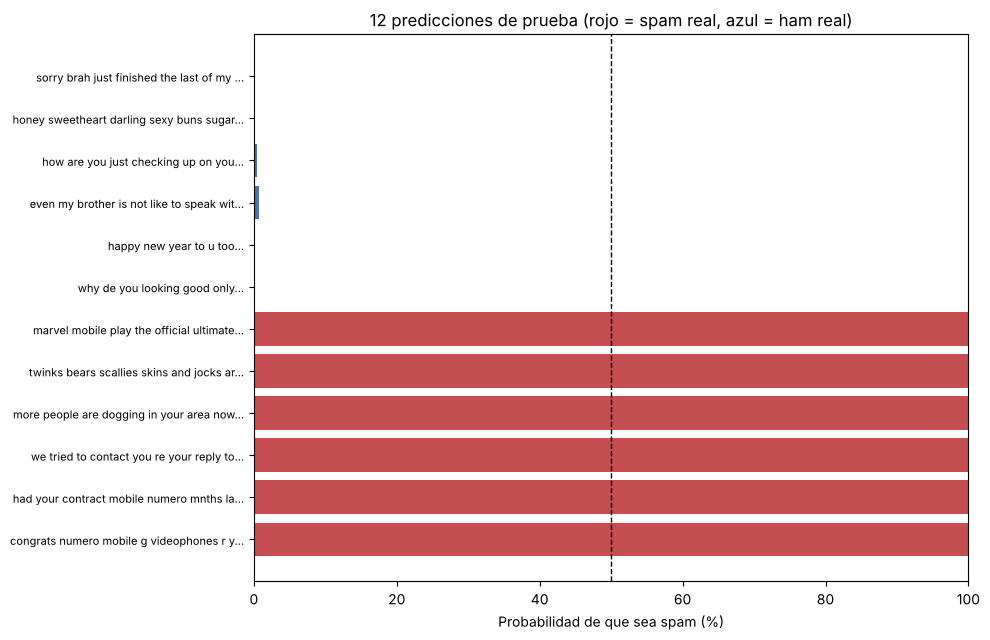

In [24]:
etiquetas = [x_test[i][:40] + "..." for i in indices]
valores = [probabilidades[i] * 100 for i in indices]
colores = ["#c44e52" if y_test[i] else "#4c72b0" for i in indices]

plt.figure(figsize=(10, 6.5))
plt.barh(range(len(indices)), valores, color=colores)
plt.yticks(range(len(indices)), etiquetas, fontsize=8)
plt.axvline(50, color="black", linestyle="--", linewidth=1)
plt.xlabel("Probabilidad de que sea spam (%)")
plt.title("12 predicciones de prueba (rojo = spam real, azul = ham real)")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Y aca pruebo con mensajes que escribi yo mismo, que no salieron del dataset, para ver si el modelo de verdad aprendio el patron o si solo se memorizo los mensajes del entrenamiento.

In [25]:
mios = [
    "Congratulations! You have won a FREE iPhone 15. Click here to claim your prize now",
    "URGENT: Your account has been suspended. Verify your details at www.secure-login.com",
    "WINNER!! You have been selected to receive a 900 prize reward. Call 09061701461 now",
    "Free entry in a weekly competition to win tickets, text WIN to 80086",
    "Hey are we still meeting tomorrow at the library?",
    "Mom says dinner is ready, come home soon",
    "Can you send me the notes from yesterday class please",
    "I will call you back in 10 minutes, im in a meeting right now"
]

limpios = np.array([limpiar_texto(m) for m in mios], dtype=object)
probs_mios = modelo.predict(limpios, verbose=0).flatten()

for m, p in zip(mios, probs_mios):
    print("[%s] %6.2f%%  |  %s" % ("SPAM" if p >= 0.5 else "ham ", p * 100, m[:68]))

[SPAM]  99.99%  |  Congratulations! You have won a FREE iPhone 15. Click here to claim 
[ham ]  13.46%  |  URGENT: Your account has been suspended. Verify your details at www.
[SPAM]  99.99%  |  WINNER!! You have been selected to receive a 900 prize reward. Call 
[SPAM]  99.99%  |  Free entry in a weekly competition to win tickets, text WIN to 80086
[ham ]   0.04%  |  Hey are we still meeting tomorrow at the library?
[ham ]   0.03%  |  Mom says dinner is ready, come home soon
[ham ]   0.06%  |  Can you send me the notes from yesterday class please
[ham ]   0.06%  |  I will call you back in 10 minutes, im in a meeting right now


De los 8 me acerto 7. El unico que se le escapo fue el de "URGENT: Your account has been suspended...", que le dio apenas 13% de probabilidad de spam.

Me puse a pensar por que y creo que es porque ese mensaje es phishing, y el dataset casi no trae de esos. El spam que tiene son premios, sorteos, tonos de celular y suscripciones, que es el spam que se usaba por SMS en esa epoca. Entonces la red aprendio muy bien ese tipo de spam pero el de "su cuenta fue suspendida" practicamente no lo vio nunca.

Igual los otros 7 los acerto, incluyendo mensajes que yo escribi de cero, asi que si esta aprendiendo el patron y no solo memorizando los mensajes del entrenamiento.

## 11. Guardado del modelo

Guardo el modelo en formato `.keras`. Como la capa `TextVectorization` esta adentro, el vocabulario se guarda junto con los pesos y no me toca guardar nada aparte.

In [26]:
import os
os.makedirs("modelo", exist_ok=True)

modelo.save("modelo/modelo_spam.keras")
print("Modelo guardado")
print("Tamaño: %.2f MB" % (os.path.getsize("modelo/modelo_spam.keras") / (1024 * 1024)))

Modelo guardado
Tamaño: 6.91 MB


In [27]:
# para bajarlo desde Colab al computador
# from google.colab import files
# files.download("modelo/modelo_spam.keras")

### Compruebo que el modelo guardado si funciona

Lo vuelvo a cargar desde el archivo y hago una prediccion, para confirmar que la app de Streamlit lo va a poder usar sin problema.

In [28]:
modelo_cargado = keras.models.load_model("modelo/modelo_spam.keras")

prueba = ["WINNER! Claim your free prize now, call 09061701461",
          "see you at class tomorrow, bring the laptop"]

limpios = np.array([limpiar_texto(m) for m in prueba], dtype=object)
resultado = modelo_cargado.predict(limpios, verbose=0).flatten()

for m, p in zip(prueba, resultado):
    print("%s -> %s (%.2f%% de spam)" % (m[:50], "SPAM" if p >= 0.5 else "ham", p * 100))

WINNER! Claim your free prize now, call 0906170146 -> SPAM (99.99% de spam)
see you at class tomorrow, bring the laptop -> ham (0.08% de spam)


## 12. Conclusiones

- La LSTM quedo con **98% de accuracy** y un **F1 de 0.92 en la clase spam**, que es la que importa. El ROC-AUC quedo por encima de 0.97, o sea que separa muy bien las dos clases.
- Lo que mas ayudo no fue la arquitectura sino la **limpieza**. Cuando cambie los numeros y los links por palabras clave (`numerolargo`, `link`, `libras`) el modelo mejoro, porque esas marcas son justamente las señales mas fuertes del spam y antes se estaban perdiendo.
- El dataset desbalanceado si se notaba: en las primeras pruebas sin pesos de clase el recall de spam quedaba mas bajo porque a la red le salia barato decir "ham" todo el tiempo. Con `class_weight` eso se corrigio.
- Los pocos errores que quedan son casi todos mensajes cortos y ambiguos, del estilo de un ham que dice "call me now" y se parece a la forma en que hablan los mensajes de spam.
- Probando con mensajes mios note que el modelo detecta muy bien el spam de premios y sorteos, pero se le escapa el **phishing** (del tipo "su cuenta fue suspendida, verifique sus datos"). Es logico, el dataset casi no trae ese tipo de mensajes porque es de la epoca en que el spam por SMS era mas que todo publicidad y concursos.
- Una limitacion clara es que el dataset es de mensajes en **ingles** y de hace varios años, entonces con mensajes en español o con el spam de ahora (que llega mas que todo por WhatsApp) no funcionaria igual de bien. Para eso tocaria conseguir un dataset en español y reentrenar.

El modelo entrenado se usa en la aplicacion de Streamlit que esta en el archivo `app.py` del repositorio.